# 06 · Four input fields: raw forecasts vs ours vs MET Nordic

**Inputs.** Every model enters with the same four fields: 10 m wind (10u, 10v), mean sea-level
pressure (msl) and 2 m temperature (2t).

**Compared.**
* the four raw forecasts: IFS, AIFS (0.25°, bilinear at the stations), MEPS, AROME-Arctic (2.5 km,
  nearest cell);
* **ours**: the dual-scale GNO (SFNO global + FNO regional encoders, width 16, 8 × 16 modes, GNO
  readout 60 / 10 km, zero-initialised MLP head), trained on the four-field inputs of all four models;
  3 seeds × 5 spatial folds, each station predicted by the fold that did not train on it;
* the MET Nordic 1 km analysis at the valid time (bilinear at the stations).

**Score.** Vector RMSE (m/s) of the 10 m wind against the observations at the held-out stations, every
forecast on the same samples (test runs where all four models, the observation and the MET Nordic
analysis exist). Curves: ours is the seed-mean forecast. Overall: RMSE over all lead times; for ours
the mean ± s.d. of the three seeds' RMSE.

| period | train | validation | test |
|---|---|---|---|
| original | 2024-03-01 – 2024-12-31 | 2025-01-01 – 03-31 | 2025-04-01 – 09-12 |
| extended | 2024-03-01 – 2025-12-31 | 2026-01-01 – 03-31 | 2026-04-01 – 11-14 |

In [1]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, '../scripts/report_unified_inputs')
import duallib as D
from station_results import metnordic_at_stations

ORANGE, INK, INK2 = '#eb6834', '#0b0b0b', '#52514e'
MM = 1 / 25.4
FIG = Path('figs/06'); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    'figure.dpi': 220, 'savefig.dpi': 600, 'figure.facecolor': 'white', 'savefig.facecolor': 'white',
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 7, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5,
    'axes.linewidth': .6, 'xtick.major.width': .6, 'ytick.major.width': .6, 'xtick.major.size': 2.5,
    'ytick.major.size': 2.5, 'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
    'lines.linewidth': 1.2, 'pdf.fonttype': 42, 'svg.fonttype': 'none'})

def save(fig, name):
    fig.savefig(FIG / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight')

OURS = f'rg60_rr10_{D.SMALL}_head-mlp'            # dual-scale GNO, four fields
# name: (colour, line style, marker)
STYLE = {'IFS': ('#2a78d6', '-', None), 'AIFS': ('#1baf7a', '-', None),
         'MEPS': ('#9b59b6', '-', None), 'AROME-Arctic': ('#c8a400', '-', None),
         'MET Nordic analysis': (INK2, (0, (4, 1.5)), None), 'ours': (ORANGE, '-', 'o')}

PER = {}
for per in ('original', 'extended'):
    P = D.Period(per)
    mn = metnordic_at_stations(P)
    P.mask &= np.isfinite(mn).all(-1)               # samples with a MET Nordic analysis
    seeds = P.seeds(P.dual, OURS)
    F = {'IFS': P.raw['ifs'], 'AIFS': P.raw['aifs'], 'MEPS': P.raw['meps'], 'AROME-Arctic': P.raw['arome'],
         'MET Nordic analysis': mn, 'ours': np.mean(list(seeds.values()), 0)}
    PER[per] = dict(P=P, F=F, seeds=seeds)
    print(f'{per}: {P.mask.sum():,} samples, {P.mask.any((1, 2)).sum()} runs, '
          f'{P.mask.any((0, 1)).sum()} stations, {len(seeds)} seeds of ours')

original: 367,427 samples, 328 runs, 98 stations, 3 seeds of ours


extended: 509,729 samples, 452 runs, 97 stations, 3 seeds of ours


## 1 · RMSE by lead time and over all lead times, both test periods together

The two test periods (Apr–Sep 2025 and Apr–Nov 2026) are pooled into one sample set: every RMSE is
over the samples of both. Ours is scored on each period with the model trained for that period.

877,156 samples in both periods, seeds of ours [0, 1, 2]


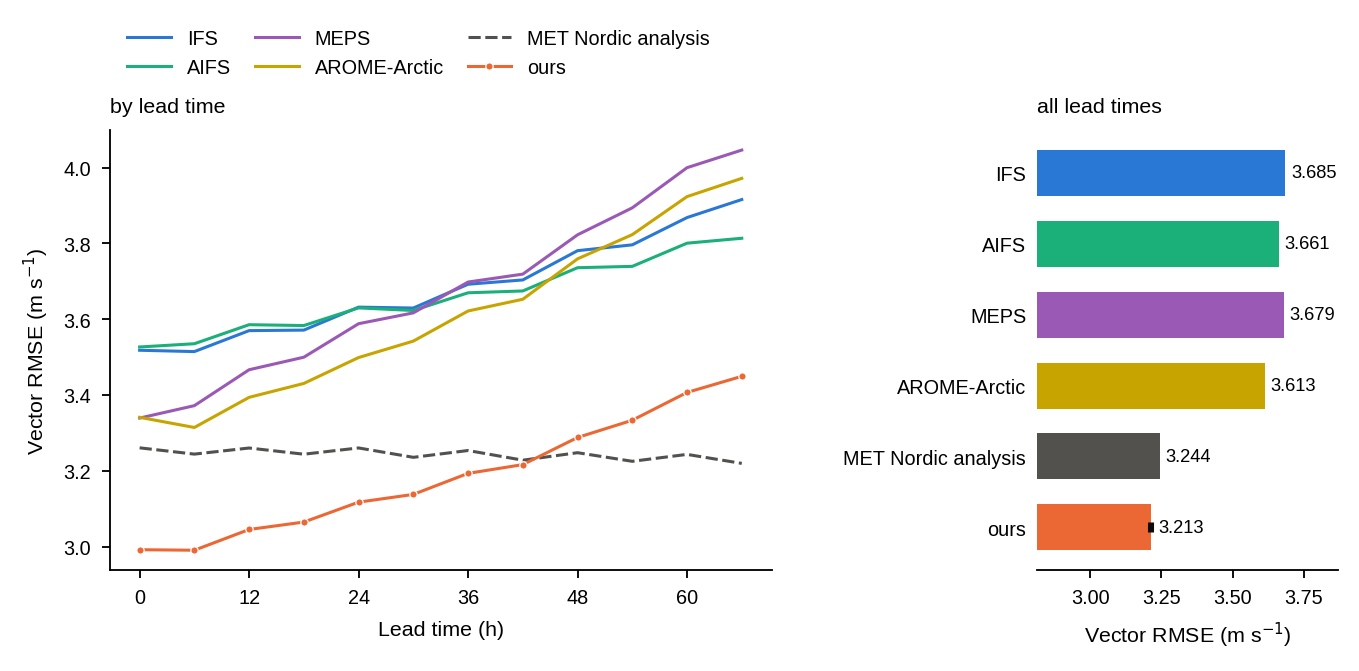

In [2]:
LEADS = PER['original']['P'].leads
assert (PER['extended']['P'].leads == LEADS).all()

def sq(per, f):
    # squared vector error (N, L, S) and mask of one period
    P = PER[per]['P']
    return np.sum((f - P.obs) ** 2, -1), P.mask

def rmse_pooled(fs, lead=None):
    # RMSE over both periods; fs = {period: forecast}; lead index or None for all leads
    s = n = 0
    for per, f in fs.items():
        e, m = sq(per, f)
        if lead is not None:
            m = m & (np.arange(len(LEADS)) == lead)[None, :, None]
        s += e[m].sum(); n += m.sum()
    return float(np.sqrt(s / n))

ALL = {k: {per: d['F'][k] for per, d in PER.items()} for k in STYLE}
SEEDS = sorted(set(PER['original']['seeds']) & set(PER['extended']['seeds']))
print(f"{sum(d['P'].mask.sum() for d in PER.values()):,} samples in both periods, seeds of ours {SEEDS}")

lead_tab = pd.DataFrame({k: [rmse_pooled(fs, j) for j in range(len(LEADS))] for k, fs in ALL.items()},
                        index=pd.Index(LEADS, name='lead (h)'))
rows = []
for k, fs in ALL.items():
    if k.startswith('ours'):
        v = np.array([rmse_pooled({per: PER[per]['seeds'][s] for per in PER}) for s in SEEDS])
        rows.append({'forecast': k, 'RMSE, all leads': v.mean(), 'seed s.d.': v.std()})
    else:
        rows.append({'forecast': k, 'RMSE, all leads': rmse_pooled(fs), 'seed s.d.': np.nan})
tab = pd.DataFrame(rows).set_index('forecast')

fig, axs = plt.subplots(1, 2, figsize=(183 * MM, 66 * MM), gridspec_kw=dict(width_ratios=[2.2, 1], wspace=.55))
ax = axs[0]
for k, (col, ls, mk) in STYLE.items():
    ax.plot(LEADS, lead_tab[k], color=col, ls=ls, marker=mk, ms=2.4, mec='white', mew=.4, lw=1.0, label=k)
ax.set(xlabel='Lead time (h)', ylabel='Vector RMSE (m s$^{-1}$)', xticks=LEADS[::2])
ax.set_title('by lead time', fontsize=7, loc='left')
ax.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.08), handlelength=2.2, columnspacing=1.2)

ax = axs[1]
names = list(STYLE)
for y, k in enumerate(names[::-1]):
    r, sd = tab.loc[k, 'RMSE, all leads'], tab.loc[k, 'seed s.d.']
    ax.barh(y, r, color=STYLE[k][0], height=.65)
    if np.isfinite(sd):
        ax.errorbar(r, y, xerr=sd, fmt='none', ecolor=INK, elinewidth=.7, capsize=1.5, zorder=4)
    ax.text(r + (sd if np.isfinite(sd) else 0) + .02, y, f'{r:.3f}', va='center', fontsize=6)
ax.set_yticks(range(len(names)), names[::-1])
ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
ax.set_xlim(tab['RMSE, all leads'].min() - .4, None)
ax.set_xlabel('Vector RMSE (m s$^{-1}$)')
ax.set_title('all lead times', fontsize=7, loc='left')
save(fig, 'fig1_rmse_lead_and_total')
plt.show()

**Fig. 1 | RMSE of the raw forecasts, ours and MET Nordic, four input fields, both test periods
together** (Apr–Sep 2025 and Apr–Nov 2026). Left: vector RMSE against the station observations by
lead time; right: over all lead times (error bar: s.d. over the three seeds of ours). The MET Nordic
analysis is valid at the observation time, so it has no lead time.

In [3]:
tab.round(3).to_csv(FIG / 'rmse_total.csv')
lead_tab.round(3).to_csv(FIG / 'rmse_lead.csv')
tab.round(3)

,"RMSE, all leads",seed s.d.
forecast,,
IFS,3.685,NaN
AIFS,3.661,NaN
MEPS,3.679,NaN
AROME-Arctic,3.613,NaN
MET Nordic analysis,3.244,NaN
ours,3.213,0.005


## 2 · Table by lead time

In [4]:
lead_tab.round(3)

,IFS,AIFS,MEPS,AROME-Arctic,MET Nordic analysis,ours
lead (h),,,,,,
0,3.518,3.527,3.339,3.341,3.261,2.992
6,3.515,3.535,3.372,3.314,3.244,2.990
12,3.570,3.586,3.467,3.394,3.260,3.045
18,3.571,3.583,3.500,3.431,3.244,3.065
24,3.632,3.630,3.588,3.499,3.260,3.117
30,3.630,3.623,3.617,3.542,3.236,3.138
36,3.692,3.670,3.698,3.622,3.254,3.193
42,3.704,3.675,3.719,3.653,3.228,3.216
48,3.781,3.736,3.823,3.759,3.248,3.288


## 3 · Wind field maps: one case on the MET Nordic 1 km grid

Land cells of the 1 km MET Nordic grid over Troms / Senja (every 2nd cell), for the test run with
the strongest MET Nordic wind at +24 h (original period). Every input is built at the cell as at a
station; ours is the mean of the 5 fold models and the 3 seeds (`scripts/eval_metnordic_grid.py
--configs all`, ROOT/results/metnordic/grid_eval_all.npz). Colour: wind speed; arrows: direction.
Numbers: RMSE against MET Nordic over the map.

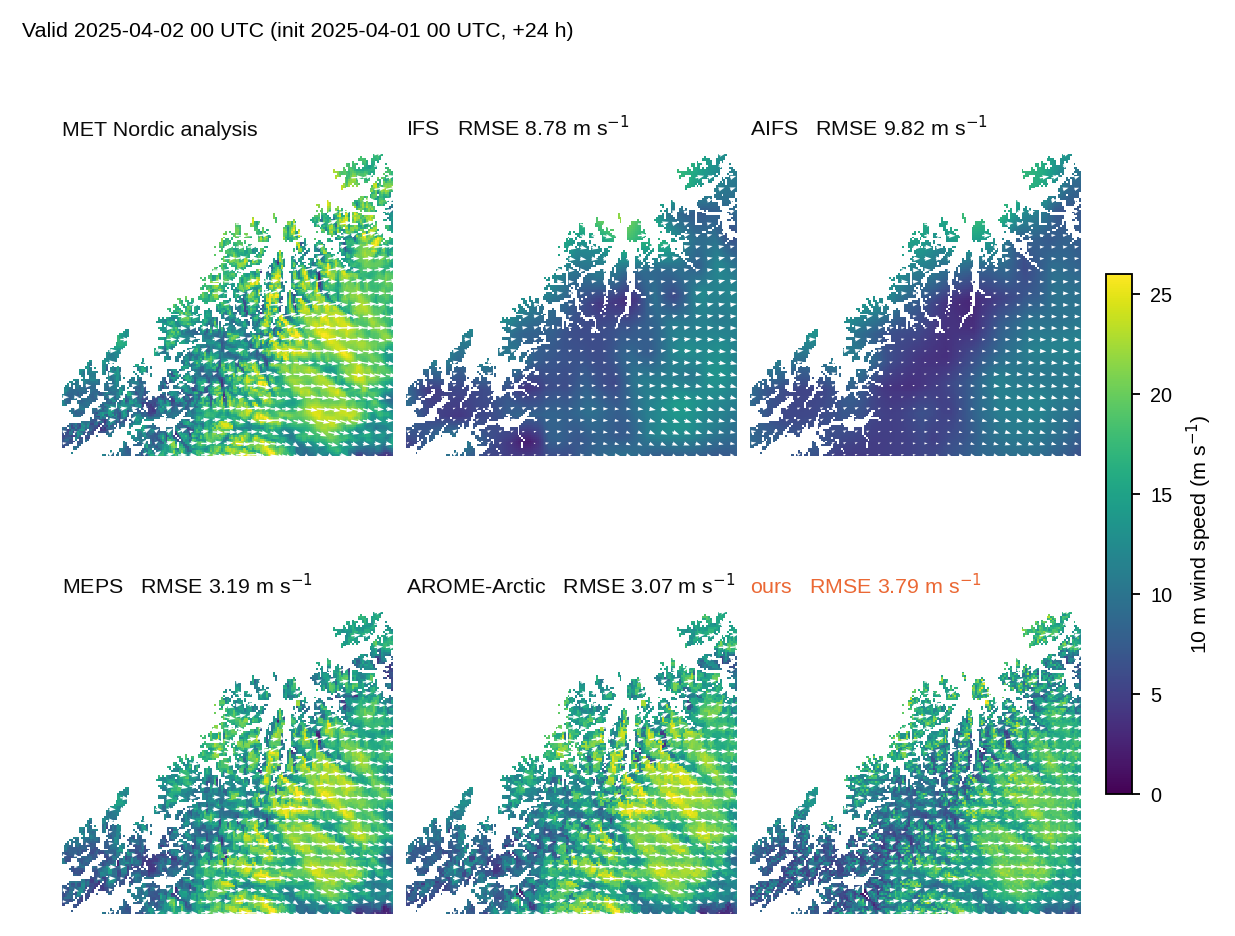

In [5]:
G = np.load(D.ROOT / 'results' / 'metnordic' / 'grid_eval_all.npz', allow_pickle=True)
iy, ix = (G['mn_y'] - G['mn_y'].min()) // int(G['step']), (G['mn_x'] - G['mn_x'].min()) // int(G['step'])
valid = pd.Timestamp(str(G['case_init'])) + pd.Timedelta(hours=24)
MAPS = {'MET Nordic analysis': G['case_truth'], 'IFS': G['case_pred_raw_ifs'], 'AIFS': G['case_pred_raw_aifs'],
        'MEPS': G['case_pred_raw_meps'], 'AROME-Arctic': G['case_pred_raw_arome'], 'ours': G['case_pred_dual_small_mlp']}

def grid(v):
    a = np.full((iy.max() + 1, ix.max() + 1), np.nan, np.float32)
    a[iy, ix] = v
    return a

vmax = np.ceil(np.nanpercentile(np.hypot(*G['case_truth'].T), 99.5))
fig, axs = plt.subplots(2, 3, figsize=(183 * MM, 130 * MM), gridspec_kw=dict(wspace=.04, hspace=.12))
Y, X = np.mgrid[:iy.max() + 1, :ix.max() + 1]
q = 6                                                   # one arrow every q map cells (12 km)
for ax, (k, uv) in zip(axs.flat, MAPS.items()):
    U, V = grid(uv[:, 0]), grid(uv[:, 1])
    im = ax.pcolormesh(np.hypot(U, V), cmap='viridis', vmin=0, vmax=vmax, shading='nearest', rasterized=True)
    ax.quiver(X[::q, ::q], Y[::q, ::q], U[::q, ::q], V[::q, ::q], color='white', scale=vmax * 22,
              width=.004, headwidth=3.5)
    err = '' if k.startswith('MET') else \
        f"   RMSE {np.sqrt(np.mean(np.sum((uv - G['case_truth']) ** 2, -1))):.2f} m s$^{{-1}}$"
    ax.set_title(k + err, fontsize=7, loc='left', color=ORANGE if k == 'ours' else INK)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
cb = fig.colorbar(im, ax=axs, shrink=.6, pad=.02)
cb.set_label('10 m wind speed (m s$^{-1}$)')
fig.suptitle(f'Valid {valid:%Y-%m-%d %H} UTC (init {pd.Timestamp(str(G["case_init"])):%Y-%m-%d %H} UTC, +24 h)',
             fontsize=7, x=.1, ha='left', y=.95)
save(fig, 'fig2_wind_maps')
plt.show()

**Fig. 2 | 10 m wind field of one case on the 1 km MET Nordic grid.** MET Nordic analysis (top left)
and the +24 h forecasts of the four raw models and ours at the same valid time; land cells only.
Colour: wind speed; arrows: wind direction and speed; numbers: RMSE against MET Nordic over the map.
Ours is applied at every cell as at a station.

## 4 · Where on the grid ours is closer to MET Nordic

Per 1 km point, over the whole original test period: RMSE change against MET Nordic of ours vs each
raw model (blue: ours closer to MET Nordic). Triangles: stations inside the grid. Note that MET Nordic
is built on MEPS, so it is not independent of the regional models.

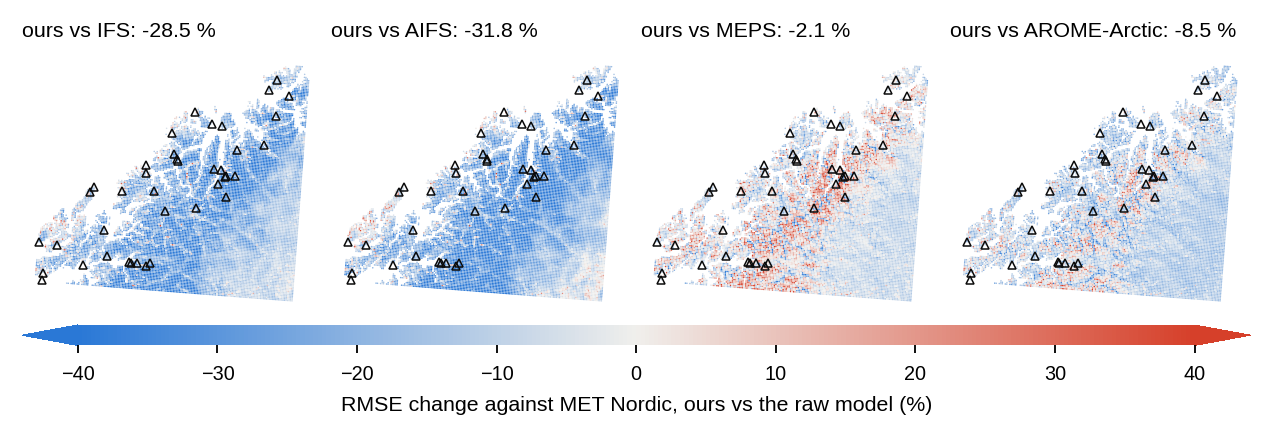

,"RMSE vs MET Nordic, grid (m/s)"
IFS,2.907
AIFS,3.051
MEPS,2.125
AROME-Arctic,2.274
ours,2.080


In [6]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cnt = G['cnt_pt']
per_pt = lambda k: np.sqrt(G[f'se_pt_{k}'] / np.maximum(cnt, 1))
tot_g = lambda k: np.sqrt(G[f'se_pt_{k}'].sum() / cnt.sum())
xy, sxy, sin_ = G['xy'], G['st_xy'], G['st_in']
cmap = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#d6402a'])
norm = TwoSlopeNorm(vcenter=0, vmin=-40, vmax=40)
fig, axs = plt.subplots(1, 4, figsize=(183 * MM, 62 * MM), gridspec_kw=dict(wspace=.03))
for ax, (m, lab) in zip(axs, [('ifs', 'IFS'), ('aifs', 'AIFS'), ('meps', 'MEPS'), ('arome', 'AROME-Arctic')]):
    c = 100 * (per_pt('dual_small_mlp') / per_pt(f'raw_{m}') - 1)
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=c, s=.25, cmap=cmap, norm=norm, linewidths=0, rasterized=True)
    ax.plot(sxy[sin_, 0], sxy[sin_, 1], '^', ms=2.6, mfc='none', mec=INK, mew=.5)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
    ax.set_title(f"ours vs {lab}: {100 * (tot_g('dual_small_mlp') / tot_g(f'raw_{m}') - 1):+.1f} %",
                 fontsize=7, loc='left')
cb = fig.colorbar(sc, ax=axs, orientation='horizontal', fraction=.05, pad=.03, aspect=60, extend='both')
cb.set_label('RMSE change against MET Nordic, ours vs the raw model (%)')
cb.outline.set_visible(False)
save(fig, 'fig3_grid_change')
plt.show()
pd.Series({k: tot_g(v) for k, v in [('IFS', 'raw_ifs'), ('AIFS', 'raw_aifs'), ('MEPS', 'raw_meps'),
          ('AROME-Arctic', 'raw_arome'), ('ours', 'dual_small_mlp')]}, name='RMSE vs MET Nordic, grid (m/s)').round(3).to_frame()

**Fig. 3 | RMSE change of ours against MET Nordic on the 1 km grid,** per point, relative to each raw
model (original test period). Title: change over the whole grid.

## 5 · Encoder size (existing runs)

All four-field dual-scale GNO, MLP head, GNO readout 60 / 10 km; only the encoder width and number of
Fourier modes change (both branches the same). Ours: width 16, 8 × 16 modes. The width 8 and 4 × 8
variants exist only with the θ + mountain features and for one seed of the original period; the
width-64 model for one seed of both periods. Station RMSE: both test periods pooled where both exist.

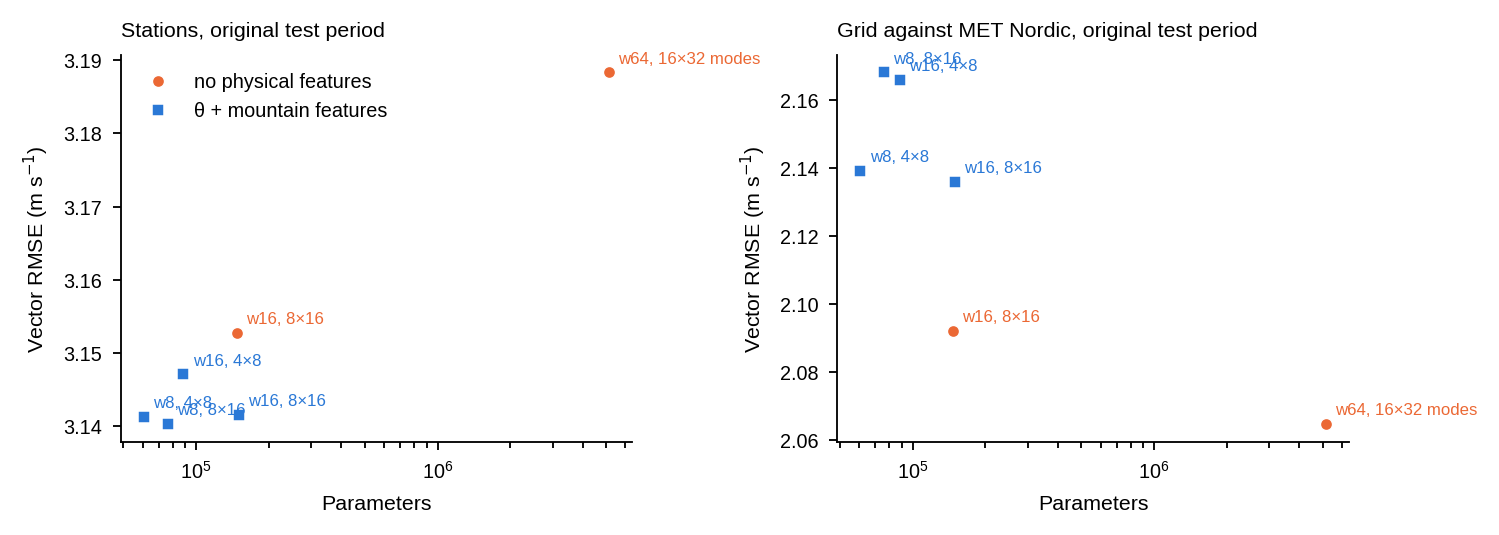

,parameters,seeds (orig / ext),original,extended,both periods,grid vs MET Nordic
encoder,,,,,,
"w64, 16×32 modes",5140482,1 / 1,3.188,3.316,3.263,2.065
"w16, 8×16 (ours)",147234,3 / 3,3.153,3.256,3.213,2.092
"w16, 8×16 + θ/mtn",150050,3 / 3,3.142,3.255,3.208,2.136
"w16, 4×8 + θ/mtn",88610,1 / 0,3.147,NaN,NaN,2.166
"w8, 8×16 + θ/mtn",76114,1 / 0,3.140,NaN,NaN,2.168
"w8, 4×8 + θ/mtn",60754,1 / 0,3.141,NaN,NaN,2.139


In [7]:
S = D.SMALL
ENC = [  # label, run tag, physical features, name in grid_eval_all
    ('w64, 16×32 modes', 'rg60_rr10_z0_head-mlp', False, 'dual_mlp_gno'),
    ('w16, 8×16 (ours)', f'rg60_rr10_{S}_head-mlp', False, 'dual_small_mlp'),
    ('w16, 8×16 + θ/mtn', f'rg60_rr10_phys-all_{S}_head-mlp', True, 'dual_small_mlp_phys'),
    ('w16, 4×8 + θ/mtn', 'rg60_rr10_phys-all_r16m4x8_g16m4x8_z0_head-mlp', True, 'dual_w16m4x8_mlp_phys'),
    ('w8, 8×16 + θ/mtn', 'rg60_rr10_phys-all_r8m8x16_g8m8x16_z0_head-mlp', True, 'dual_w8m8x16_mlp_phys'),
    ('w8, 4×8 + θ/mtn', 'rg60_rr10_phys-all_r8m4x8_g8m4x8_z0_head-mlp', True, 'dual_w8m4x8_mlp_phys')]
rows, ENCF = [], {}
for lab, tag, phys, gk in ENC:
    fs = {per: d['P'].seeds(d['P'].dual, tag) for per, d in PER.items()}
    ENCF[lab] = fs
    s0 = min(fs['original'])
    r = {'encoder': lab, 'parameters': PER['original']['P'].n_params('dual', f'dual_sfno-fno_g0_s{s0}_{tag}_lr1e-05'),
         'seeds (orig / ext)': f"{len(fs['original'])} / {len(fs['extended'])}"}
    for per, d in PER.items():
        r[per] = np.mean([d['P'].rmse(f) for f in fs[per].values()]) if fs[per] else np.nan
    both = sorted(set(fs['original']) & set(fs['extended']))
    r['both periods'] = np.mean([rmse_pooled({per: fs[per][s] for per in PER}) for s in both]) if both else np.nan
    r['grid vs MET Nordic'] = float(np.sqrt(G[f'se_seed_{gk}'] / cnt.sum()).mean())
    rows.append(r)
enc = pd.DataFrame(rows).set_index('encoder')
enc.round(3).to_csv(FIG / 'encoder_size.csv')

fig, axs = plt.subplots(1, 2, figsize=(183 * MM, 58 * MM), gridspec_kw=dict(wspace=.4))
for ax, col, ttl in zip(axs, ['original', 'grid vs MET Nordic'],
                        ['Stations, original test period', 'Grid against MET Nordic, original test period']):
    for phys, c, mk, lab in [(False, ORANGE, 'o', 'no physical features'), (True, '#2a78d6', 's', 'θ + mountain features')]:
        e = enc[np.array([p_ for _, _, p_, _ in ENC]) == phys]
        ax.plot(e['parameters'], e[col], mk, color=c, ms=4, mec='white', mew=.5, label=lab, ls='')
        for name_, r in e.iterrows():
            ax.annotate(name_.split(' +')[0].replace(' (ours)', ''), (r['parameters'], r[col]), fontsize=5.5,
                        xytext=(3, 3), textcoords='offset points', color=c)
    ax.set_xscale('log'); ax.set_xlabel('Parameters'); ax.set_ylabel('Vector RMSE (m s$^{-1}$)')
    ax.set_title(ttl, fontsize=7, loc='left')
axs[0].legend(loc='upper left')
save(fig, 'fig4_encoder_size')
plt.show()
enc.round(3)

**Fig. 4 | Encoder size.** RMSE against the parameter count of the dual-scale GNO, at the stations
(left) and on the 1 km grid against MET Nordic (right), original test period; mean over the available
seeds.

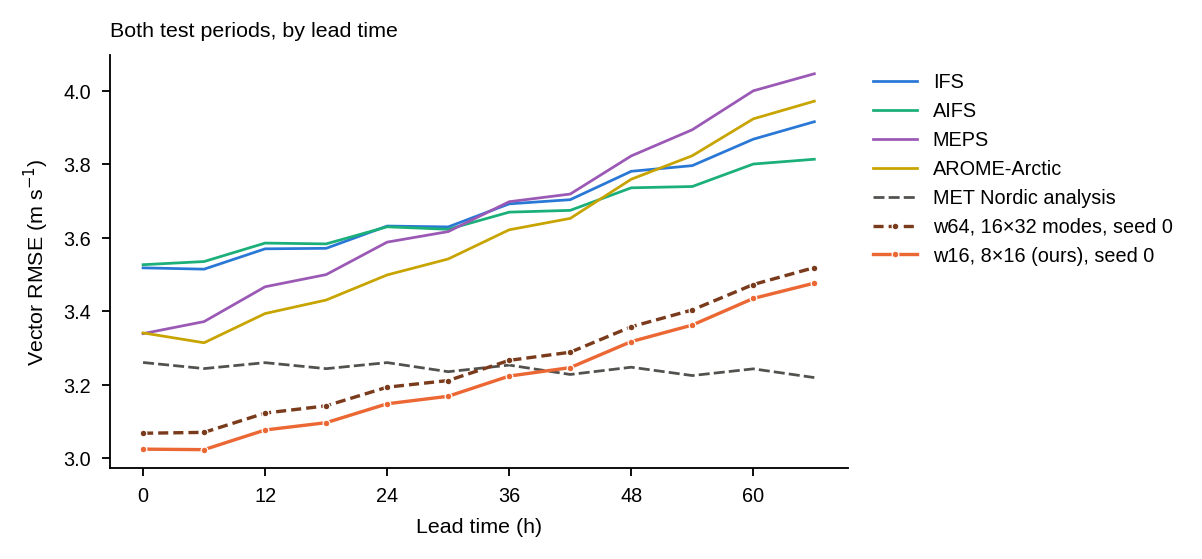

In [8]:
# by lead time, both periods pooled: width 64 vs ours (seed 0 only for both, to compare like with like)
fig, ax = plt.subplots(figsize=(110 * MM, 62 * MM))
for k in ['IFS', 'AIFS', 'MEPS', 'AROME-Arctic', 'MET Nordic analysis']:
    col, ls, mk = STYLE[k]
    ax.plot(LEADS, lead_tab[k], color=col, ls=ls, lw=.9, label=k)
for lab, c, ls in [('w64, 16×32 modes', '#7a3b1c', (0, (3, 1.5))), ('w16, 8×16 (ours)', ORANGE, '-')]:
    fs = {per: ENCF[lab][per][0] for per in PER}
    ax.plot(LEADS, [rmse_pooled(fs, j) for j in range(len(LEADS))], color=c, ls=ls, marker='o', ms=2.2,
            mec='white', mew=.4, lw=1.1, label=lab + ', seed 0')
ax.set(xlabel='Lead time (h)', ylabel='Vector RMSE (m s$^{-1}$)', xticks=LEADS[::2])
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), handlelength=2.2)
ax.set_title('Both test periods, by lead time', fontsize=7, loc='left')
save(fig, 'fig5_encoder_lead')
plt.show()